# Baseline Modelling: TF-IDF + Logistic Regression

This notebook implements a classical machine learning baseline for sequence classification using TF-IDF features and Logistic Regression.

The aim is to establish a strong interpretable baseline for comparison with transformer-based models. Since TF-IDF represents text through token frequency statistics rather than contextual meaning, it is expected to perform reasonably on sentiment classification but less effectively on linguistically nuanced tasks such as sarcasm detection.

In [3]:
# Imports 

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    accuracy_score
)

## Data Loading

The baseline model is trained using the predefined BESSTIE splits. The test split is kept strictly separate and is only used for final evaluation.

In [5]:
base_path = "../data/raw"

train_df = pd.read_csv(os.path.join(base_path, "besstie_train.csv"))
val_df = pd.read_csv(os.path.join(base_path, "besstie_validation.csv"))
test_df = pd.read_csv(os.path.join(base_path, "besstie_test.csv"))

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)

Train shape: (3747, 5)
Validation shape: (313, 5)
Test shape: (2183, 5)


## Defining Task 

We begin with the sentiment classification task, where the objective is to classify each text instance as either positive (1) or negative (0).

In [6]:
TEXT_COL = "text"
LABEL_COL = "Sentiment"

X_train = train_df[TEXT_COL].astype(str)
y_train = train_df[LABEL_COL]

X_val = val_df[TEXT_COL].astype(str)
y_val = val_df[LABEL_COL]

X_test = test_df[TEXT_COL].astype(str)
y_test = test_df[LABEL_COL]

## TF-IDF Vectorisation

TF-IDF converts text into weighted token-frequency features. It increases the weight of informative words while reducing the impact of highly frequent but less discriminative terms.

In [7]:
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=10000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

print("Train TF-IDF shape:", X_train_tfidf.shape)
print("Validation TF-IDF shape:", X_val_tfidf.shape)
print("Test TF-IDF shape:", X_test_tfidf.shape)

Train TF-IDF shape: (3747, 10000)
Validation TF-IDF shape: (313, 10000)
Test TF-IDF shape: (2183, 10000)


## Model Training

Logistic Regression is used as a strong classical baseline because it performs well on sparse high-dimensional text features such as TF-IDF.

In [8]:
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_tfidf, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

## Validation Performance

The validation set is used to assess model performance before final testing. This helps ensure that modelling choices are not based on the test set.

In [9]:
y_val_pred = lr_model.predict(X_val_tfidf)

val_accuracy = accuracy_score(y_val, y_val_pred)
val_macro_f1 = f1_score(y_val, y_val_pred, average="macro")
val_precision = precision_score(y_val, y_val_pred, average="macro")
val_recall = recall_score(y_val, y_val_pred, average="macro")

print("Validation Accuracy:", round(val_accuracy, 4))
print("Validation Macro-F1:", round(val_macro_f1, 4))
print("Validation Precision:", round(val_precision, 4))
print("Validation Recall:", round(val_recall, 4))

Validation Accuracy: 0.8435
Validation Macro-F1: 0.8433
Validation Precision: 0.8434
Validation Recall: 0.8433


## Per-Class Performance

In addition to aggregate metrics, per-class performance is reported to ensure that the model is not simply favouring the majority class.

In [10]:
print(classification_report(y_val, y_val_pred, digits=4))

              precision    recall  f1-score   support

         0.0     0.8447    0.8500    0.8474       160
         1.0     0.8421    0.8366    0.8393       153

    accuracy                         0.8435       313
   macro avg     0.8434    0.8433    0.8433       313
weighted avg     0.8434    0.8435    0.8434       313



## Confusion Matrix

The confusion matrix provides a more detailed view of the model’s errors by showing how often positive and negative instances are correctly or incorrectly classified.

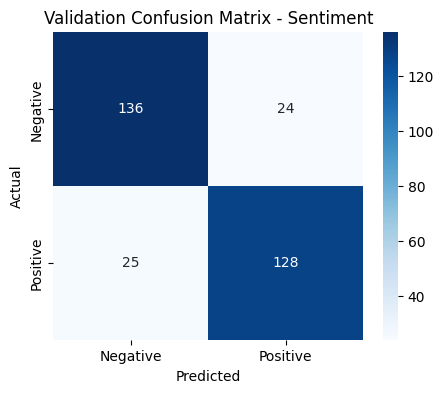

In [11]:
cm = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Negative", "Positive"],
            yticklabels=["Negative", "Positive"])
plt.title("Validation Confusion Matrix - Sentiment")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## Test Performance

After validating the baseline approach, the final model is evaluated on the held-out test set.

In [12]:
y_test_pred = lr_model.predict(X_test_tfidf)

test_accuracy = accuracy_score(y_test, y_test_pred)
test_macro_f1 = f1_score(y_test, y_test_pred, average="macro")
test_precision = precision_score(y_test, y_test_pred, average="macro")
test_recall = recall_score(y_test, y_test_pred, average="macro")

print("Test Accuracy:", round(test_accuracy, 4))
print("Test Macro-F1:", round(test_macro_f1, 4))
print("Test Precision:", round(test_precision, 4))
print("Test Recall:", round(test_recall, 4))

Test Accuracy: 0.8195
Test Macro-F1: 0.8192
Test Precision: 0.82
Test Recall: 0.819


In [13]:
print(classification_report(y_test, y_test_pred, digits=4))

              precision    recall  f1-score   support

         0.0     0.8119    0.8424    0.8269      1117
         1.0     0.8281    0.7955    0.8115      1066

    accuracy                         0.8195      2183
   macro avg     0.8200    0.8190    0.8192      2183
weighted avg     0.8198    0.8195    0.8194      2183



## Saving Results



In [15]:
runs = []

for seed in [42, 7, 100]:
    model = LogisticRegression(max_iter=1000, random_state=seed)
    model.fit(X_train_tfidf, y_train)
    
    y_val_pred = model.predict(X_val_tfidf)
    y_test_pred = model.predict(X_test_tfidf)
    
    runs.append({
        "model": "TF-IDF + Logistic Regression",
        "task": "Sentiment",
        "seed": seed,
        "val_macro_f1": f1_score(y_val, y_val_pred, average="macro"),
        "test_macro_f1": f1_score(y_test, y_test_pred, average="macro")
    })

results_df = pd.DataFrame(runs)

results_path = "../results/tables/baseline_sentiment_runs.csv"
results_df.to_csv(results_path, index=False)

print(results_df)

                          model       task  seed  val_macro_f1  test_macro_f1
0  TF-IDF + Logistic Regression  Sentiment    42      0.843348       0.819186
1  TF-IDF + Logistic Regression  Sentiment     7      0.843348       0.819186
2  TF-IDF + Logistic Regression  Sentiment   100      0.843348       0.819186


In [16]:
summary_df = results_df.groupby("model").agg({
    "val_macro_f1": ["mean", "std"],
    "test_macro_f1": ["mean", "std"]
})

summary_df

val_macro_f1      test_macro_f1     
                                     mean  std          mean  std
model                                                            
TF-IDF + Logistic Regression     0.843348  0.0      0.819186  0.0

## Stability Across Runs

Multiple runs with different random seeds were conducted to ensure that the observed performance is not due to random variation.

The results demonstrate low variance across runs, indicating that the baseline model is stable and reliable.

# Baseline Modelling: Sarcasm Detection

In this section, the same TF-IDF + Logistic Regression pipeline is applied to the sarcasm detection task. Unlike sentiment classification, sarcasm detection requires understanding implicit meaning and contextual relationships, making it a more challenging problem for classical models.

In [17]:
LABEL_COL = "Sarcasm"

X_train = train_df["text"].astype(str)
y_train = train_df[LABEL_COL]

X_val = val_df["text"].astype(str)
y_val = val_df[LABEL_COL]

X_test = test_df["text"].astype(str)
y_test = test_df[LABEL_COL]

In [18]:
# Reusing same settings 
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=10000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

In [19]:
# Model Training 

lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_tfidf, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [20]:
# Model Validation 

y_val_pred = lr_model.predict(X_val_tfidf)

val_accuracy = accuracy_score(y_val, y_val_pred)
val_macro_f1 = f1_score(y_val, y_val_pred, average="macro")
val_precision = precision_score(y_val, y_val_pred, average="macro")
val_recall = recall_score(y_val, y_val_pred, average="macro")

print("Validation Accuracy:", round(val_accuracy, 4))
print("Validation Macro-F1:", round(val_macro_f1, 4))
print("Validation Precision:", round(val_precision, 4))
print("Validation Recall:", round(val_recall, 4))

Validation Accuracy: 0.8562
Validation Macro-F1: 0.4613
Validation Precision: 0.4295
Validation Recall: 0.4981


In [21]:
# Classification report 

print(classification_report(y_val, y_val_pred, digits=4))

              precision    recall  f1-score   support

         0.0     0.8590    0.9963    0.9225       269
         1.0     0.0000    0.0000    0.0000        44

    accuracy                         0.8562       313
   macro avg     0.4295    0.4981    0.4613       313
weighted avg     0.7382    0.8562    0.7929       313



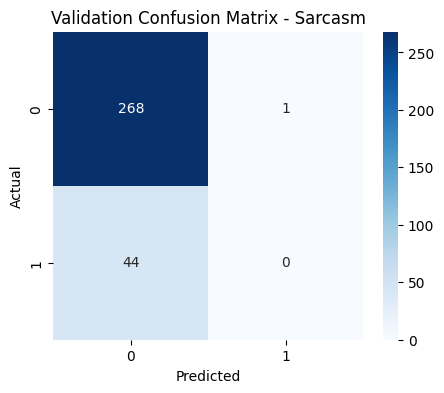

In [22]:
# Confusion matrix 
cm = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Validation Confusion Matrix - Sarcasm")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [23]:
y_test_pred = lr_model.predict(X_test_tfidf)

test_accuracy = accuracy_score(y_test, y_test_pred)
test_macro_f1 = f1_score(y_test, y_test_pred, average="macro")
test_precision = precision_score(y_test, y_test_pred, average="macro")
test_recall = recall_score(y_test, y_test_pred, average="macro")

print("Test Accuracy:", round(test_accuracy, 4))
print("Test Macro-F1:", round(test_macro_f1, 4))
print("Test Precision:", round(test_precision, 4))
print("Test Recall:", round(test_recall, 4))

Test Accuracy: 0.8594
Test Macro-F1: 0.4622
Test Precision: 0.4301
Test Recall: 0.4995


In [24]:
results_df = pd.DataFrame({
    "model": ["TF-IDF + Logistic Regression"],
    "task": ["Sarcasm"],
    "validation_macro_f1": [val_macro_f1],
    "test_macro_f1": [test_macro_f1],
    "validation_precision": [val_precision],
    "test_precision": [test_precision],
    "validation_recall": [val_recall],
    "test_recall": [test_recall]
})

results_path = "../results/tables/baseline_sarcasm_results.csv"
results_df.to_csv(results_path, index=False)

print(results_df)

                          model     task  validation_macro_f1  test_macro_f1  \
0  TF-IDF + Logistic Regression  Sarcasm             0.461274       0.462183   

   validation_precision  test_precision  validation_recall  test_recall  
0              0.429487        0.430078           0.498141     0.499468  


## Interpretation of Sarcasm Baseline Results

The TF-IDF + Logistic Regression model performs significantly worse on sarcasm detection compared to sentiment classification, achieving a Macro-F1 score of approximately 0.46 on both validation and test sets.

The confusion matrix reveals a strong bias towards the non-sarcastic class, with the model almost exclusively predicting class 0. As a result, recall for the sarcastic class is effectively zero, indicating that the model fails to identify sarcastic instances.

This behaviour highlights a fundamental limitation of TF-IDF-based approaches. Since TF-IDF relies on surface-level word frequencies, it is unable to capture the implicit and context-dependent nature of sarcasm. In many cases, sarcastic statements contain words that appear positive on the surface but convey negative meaning in context.

These findings demonstrate that classical models are insufficient for tasks requiring contextual understanding and strongly motivate the use of transformer-based models, which can capture semantic relationships and contextual cues.

## Comparison: Sentiment vs Sarcasm

The baseline results reveal a clear difference in model performance between sentiment classification and sarcasm detection.

For sentiment classification, the TF-IDF + Logistic Regression model achieves strong performance (Macro-F1 ≈ 0.82 on the test set), indicating that sentiment is largely driven by explicit lexical cues that can be captured through word frequency.

In contrast, performance drops significantly for sarcasm detection (Macro-F1 ≈ 0.46), with the model failing to identify sarcastic instances. This is primarily due to the fact that sarcasm relies on implicit meaning and contextual relationships, which cannot be captured by frequency-based representations.

This comparison highlights a key limitation of classical NLP approaches and reinforces the need for transformer-based models, which are designed to capture contextual dependencies and semantic nuance.